In [1]:
import numpy as np
import pandas as pd

import xarray as xr
import rioxarray as rioxr
import geopandas as gpd

# import netCDF4 as nc
import matplotlib.pyplot as plt

# import pycno

import glob

### Check and correct Northern Territory Data?

In [22]:
# Open the nc file
# path = '/gpfs/data/firecrew/active/Fire_Data_Assets/'
# FCCS = nc.Dataset(path+'GlobalFuelsDataset_FCCS/Global_fuelbeds_map_combined.nc')
FCCS_table = pd.read_excel('../Global_FCCS/Lookup_table.xlsx')

In [3]:
FCCS_lat = FCCS['lat'][:]
FCCS_lon = FCCS['lon'][:]

In [4]:
lat_idx = (FCCS_lat>=-30)&(FCCS_lat<=-10)
lon_idx = (FCCS_lon>=130)&(FCCS_lon<=150)
lat0 = int(np.where(lat_idx)[0][0])
lat1 = int(np.where(lat_idx)[0][-1])
lon0 = int(np.where(lon_idx)[0][0])
lon1 = int(np.where(lon_idx)[0][-1])
mesh_lat = np.meshgrid(FCCS_lon[lon_idx],FCCS_lat[lat_idx])[1]
mesh_lon = np.meshgrid(FCCS_lon[lon_idx],FCCS_lat[lat_idx])[0]

FCCS_cut = FCCS['Band1'][lat0:lat1+1,lon0:lon1+1]

In [6]:
np.unique(FCCS_cut)

masked_array(data=[      0,    1010,    1012,    1017,    1019,    1020,
                      1022,    1027,    1029,    1130,    1140,    7010,
                      7017,    7019,    7020,    7027,    7029,    7030,
                      7037,    7039,    7130,    7133,    8036,    8040,
                     14011,   14021,   14031,  911030,  911032,  911037,
                    911039,  911040,  911110,  911160,  917040,  917043,
                    917160,  921030,  921032,  921037,  921039,  921040,
                    921110,  921160,  927040,  927043,  927160,  931030,
                    931032,  931040,  931160,  937040, 9114170, 9214170,
                   9314170],
             mask=False,
       fill_value=999999,
            dtype=int32)

(-30.0, -10.0)

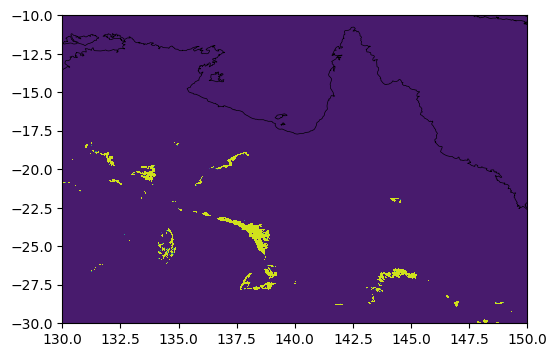

In [5]:
fig, ax = plt.subplots(figsize=(6,4))
cno = pycno.cno()
cno.draw('MWDB_Coasts_Countries_1.cnob')
c = ax.contourf(mesh_lon,mesh_lat,FCCS_cut)
ax.set_xlim([130,150])
ax.set_ylim([-30,-10])

In [325]:
WA_FT = [i for i in country_df.loc[country_df['State/Province']=='Western Australia','Fire Type'].values if type(i)==str]
len([i for i in WA_FT if 'Silviculture' in i])

1222

In [307]:
df.loc[df['Fire Type']=='Bushfire Risk','Fire Type'] = 'Bushfire Risk Management'

In [316]:
df.loc[df['State/Province']=='Northern Territory','Fire Type'] = np.nan

In [103]:
df = pd.read_csv('~/GlobalRx/Rx_Master/Rx_MASTER_v2024-05-15.csv',low_memory=False)
df2 = pd.read_csv('~/GlobalRx/Rx_Master/Rx_MASTER_v2022-12-12.csv',low_memory=False)

NT_df = df2.loc[df2['State/Province']=='Northern Territory']
NT_df_new = df[df['State/Province']=='Northern Territory']

In [114]:
ID_new = [str(NT_df_new['Latitude'].iloc[i])+str(NT_df_new['Longitude'].iloc[i])+'-'+
 str(NT_df_new['Year'].iloc[i])+str(NT_df_new['Month'].iloc[i])+str(NT_df_new['Day'].iloc[i])
 for i in range(len(NT_df_new))]
ID_old = [str(NT_df['Latitude'].iloc[i])+str(NT_df['Longitude'].iloc[i])+'-'+
 str(NT_df['Year'].iloc[i])+str(NT_df['Month'].iloc[i])+str(NT_df['Day'].iloc[i])
 for i in range(len(NT_df))]

df.loc[df['State/Province']=='Northern Territory','Land Cover (Pettinari and Chuvieco)'] = NT_df['Land Cover (Pettinari & Chuvieco)'].values
df.to_csv('~/GlobalRx/Rx_Master/Rx_MASTER_v2024-05-14.csv',index=False)

In [106]:
check_df['State/Province']

,ID,Latitude,Longitude,Year,Month,Day,Time,DOY,Country,State/Province,...,Biome (Olson),Koppen Climate,Topography,Fuelbed Classification (GFD-FCCS),WDPA Name,WDPA Governance,WDPA Ownership,WDPA Designation,WDPA IUCN Category,Timestamp of Update
4534,Rx20120310-N40.703949-W124.270845,40.703949,-124.270845,2012,3,10,NaN,70,USA,California,...,NaN,0.0,2.0,inf,South Spit,Sub-national ministry or agency,State,Wildlife Area,V,2021-02-18 00:00:00
5358,Rx20140504-N40.704567-W124.270253,40.704567,-124.270253,2014,5,4,NaN,124,USA,California,...,NaN,0.0,2.0,inf,South Spit,Sub-national ministry or agency,State,Wildlife Area,V,2021-02-18 00:00:00
5940,Rx20150226-N40.704773-W124.270097,40.704773,-124.270097,2015,2,26,NaN,57,USA,California,...,NaN,0.0,2.0,inf,South Spit,Sub-national ministry or agency,State,Wildlife Area,V,2021-02-18 00:00:00
10389,Rx20160313-N34.642991-E129.352982,34.642991,129.352982,2016,3,13,NaN,73,Japan,Senbyomaki-yama,...,NaN,14.0,28.0,inf,Iki-Tsushima,Sub-national ministry or agency,Individual landowners,Quasi National Park,V,2021-07-15 00:00:00
10390,Rx20180304-N34.642991-E129.352982,34.642991,129.352982,2018,3,4,NaN,63,Japan,Senbyomaki-yama,...,NaN,14.0,28.0,inf,Iki-Tsushima,Sub-national ministry or agency,Individual landowners,Quasi National Park,V,2021-07-15 00:00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
186298,Rx20230112-S33.827437-E151.266850,-33.827437,151.266850,2023,1,12,NaN,12,Australia,New South Wales,...,NaN,0.0,11.0,inf,Sydney Harbour,Sub-national ministry or agency,Not Reported,National Park,II,2024-01-23 18:09:26.353136
186513,Rx20230804-S33.852685-E151.267854,-33.852685,151.267854,2023,8,4,NaN,216,Australia,New South Wales,...,Temperate Broadleaf & Mixed Forests,0.0,11.0,inf,Sydney Harbour,Sub-national ministry or agency,Not Reported,National Park,II,2024-01-23 18:09:26.353136
186560,Rx20230814-S33.701630-E151.061777,-33.701630,151.061777,2023,8,14,NaN,226,Australia,New South Wales,...,Temperate Broadleaf & Mixed Forests,14.0,163.0,inf,Berowra Valley,Sub-national ministry or agency,Not Reported,National Park,II,2024-01-23 18:09:26.353136
198686,Rx20160511-S14.476037-E132.227917,-14.476037,132.227917,2016,5,11,n.a,132,Australia,Northern Territory,...,"Tropical & Subtropical Grasslands, Savannas & ...",3.0,111.0,NaN,NaN,NaN,NaN,NaN,NaN,12.12.2021


(36.0, 44.0)

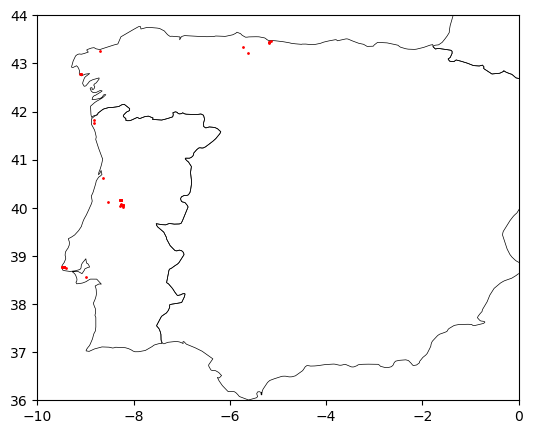

In [86]:
check_df = df[[False if len(str(i))>5 else True for i in df['Fuelbed Classification (GFD-FCCS)']]]
fig,ax = plt.subplots(figsize=(10,5))
world_shp = gpd.read_file('world_shp/world-administrative-boundaries.shp')
world_shp.plot(ax=ax,edgecolor='black',linewidth=0.5,facecolor='None',aspect='equal')
ax.scatter(check_df['Longitude'],check_df['Latitude'],s=1,c='red')
ax.set_xlim([-10,0])
ax.set_ylim([36,44])

In [ ]:
import rasterio
from rasterio.features import shapes
from shapely.geometry import shape
# import geopandas as gpd

with rasterio.open("../Global_FCCS/Global_fuelbeds_map_combined.tif") as src:
    image = src.read(1)
    mask = image != src.nodata

    # Extract polygons with values
    results = (
        (shape(geom), value)
        for geom, value in shapes(image, mask=mask, transform=src.transform)
    )

# Create GeoDataFrame with geometries and land cover types
geoms = []
values = []

for geom, val in results:
    geoms.append(geom)
    values.append(int(val))

landcover_gdf = gpd.GeoDataFrame({'land_cover': values, 'geometry': geoms}, crs="EPSG:4326")

In [3]:
FCCS_data = rioxr.open_rasterio('../Global_FCCS/Global_fuelbeds_map_combined.tif')
FCCS_data.load()
# FCCS_values = FCCS_data.values[0]

<xarray.DataArray (band: 1, y: 50625, x: 129599)> Size: 26GB
array([[[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]]], dtype=int32)
Coordinates:
  * band         (band) int64 8B 1
  * x            (x) float64 1MB -180.0 -180.0 -180.0 ... 180.0 180.0 180.0
  * y            (y) float64 405kB 83.62 83.62 83.62 ... -56.99 -57.0 -57.0
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [4]:
FCCS_interp = FCCS_data.reindex(x=np.arange(-180,180,0.25),y=np.arange(83.5,-57.25,-0.25),method='nearest')

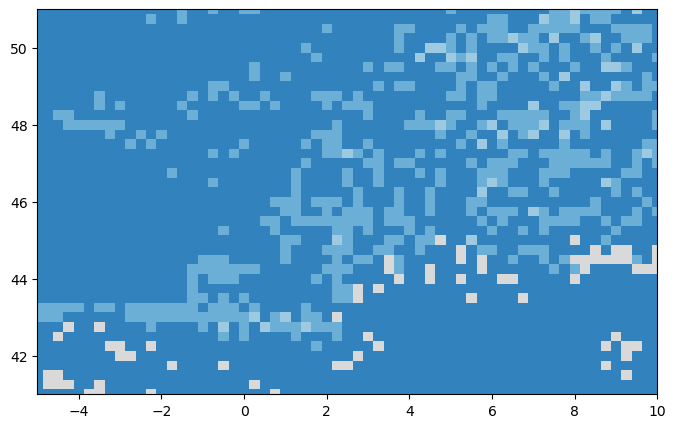

In [20]:
def quick_map(gridded_data):
    meshlon,meshlat = np.meshgrid(gridded_data['x'].values,gridded_data['y'].values)
    fig,ax = plt.subplots(figsize=(8,5))
    fig.set_facecolor(color=[0,0,0,0])
#     cno = pycno.cno(xlim=(-180,180),ylim=(-57,90))
#     cno.draw('MWDB_Coasts_Countries_1.cnob',ax=ax)
#     country_eco.plot(color=country_eco['BIOME'].map(biome_colors),ax=ax,aspect='equal')
#     country_shp.plot(facecolor='none',edgecolor='black',ax=ax)
    pc = ax.pcolormesh(meshlon,meshlat,gridded_data.values[0],cmap='tab20c')
    ax.set_xlim([-5,10])
    ax.set_ylim([41,51])
    
quick_map(FCCS_interp)

In [37]:
FCCS_interp.to_netcdf('../Global_FCCS/Global_FCCS_0.25deg.nc')

In [3]:
# df = pd.read_csv('~/GlobalRx/Rx_Master/Rx_MASTER_v2024-08-19.csv',low_memory=False)
df = pd.read_csv('Rx_Master/US_master.csv',low_memory=False)
FCCS_table = pd.read_excel('../Global_FCCS/Lookup_table.xlsx')

var = 'Fuelbed Classification (GFD-FCCS)'

# FCCS_data = rioxr.open_rasterio('../Global_FCCS/Global_fuelbeds_map_combined.tif')
# FCCS_data.load()
# FCCS_values = FCCS_data.values[0]
FCCS_lon = FCCS_data['x']
FCCS_lat = FCCS_data['y']

for i in range(0,len(df)):#range(idx,idx+len(df.iloc[idx::])):
    burn = df.loc[i]

    burn_lat = burn['Latitude']
    burn_lon = burn['Longitude']

    lat_idx = np.abs(FCCS_lat-burn_lat).argmin()
    lon_idx = np.abs(FCCS_lon-burn_lon).argmin()

    burn_FCCS = FCCS_values[lat_idx,lon_idx]
    
    try:
        burn_LC = FCCS_table.loc[FCCS_table['JOIN_VALUE']==burn_FCCS,'Land_cover'].values[0]
#         print(burn_LC)
    except:
        # If no land cover data at lat/lon of burn, check nearest 4 points
        FCCS_surr = np.array([FCCS_values[lat_idx+1,lon_idx],FCCS_values[lat_idx-1,lon_idx],
        FCCS_values[lat_idx,lon_idx+1],FCCS_values[lat_idx,lon_idx-1]])
        
        # Check which surrounding points have options
        FCCS_options = FCCS_surr[[i!=0 for i in FCCS_surr]]
        
        # If only one options, choose that one
        if len(FCCS_options)==1:
            burn_FCCS = FCCS_options[0]
            burn_LC = FCCS_table.loc[FCCS_table['JOIN_VALUE']==burn_FCCS,'Land_cover'].values[0]
#             print(burn_LC)
        # If more than one option:
        elif len(FCCS_options)>1:
            # Choose the one that most frequently occurs; if same frequency occurrence, chooses the first one
            options,counts = np.unique(FCCS_options,return_counts=True)
            max_idx = np.argmax(counts)
            burn_FCCS = options[max_idx]
            burn_LC = FCCS_table.loc[FCCS_table['JOIN_VALUE']==burn_FCCS,'Land_cover'].values[0]
#             print(burn_LC)
        else:
            print(burn_FCCS)
            continue
    
    df.loc[i,var] = burn_LC
    
    i+=1
    
    version_date = str(pd.Timestamp.today().date())
    # Save every 1000th iteration
    if i%1000 == 0:
#         df.to_csv('Rx_Master/Rx_MASTER_v'+version_date+'.csv',index=False)
        print(i)

# df.to_csv('Rx_Master/Rx_MASTER_v'+version_date+'.csv',index=False)
df.to_csv('Rx_Master/US_master.csv',index=False)

0
0
0
0
0
1000
0
2000
0
3000
4000
0
0
0
0
0
0
0
0
0
0
5000
0
6000
0
0
0
0
0
0
0
0
0
0
0
7000
0
0
0
0
0
0
8000
9000
10000
0
0
0
0
11000
0
0
0
12000
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
13000
0
0
14000
15000
0
0
0
0
0
0
16000
0
0
0
17000
18000
19000
0
20000
0
0
0
0
0
0
0
0
0
0
0
0
21000
0
22000
23000
24000
0
0
25000
0
0
0
26000
0
27000
28000
29000
30000
0
0
0
31000
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
32000
0
0
33000
0
0
0
34000
0
0
35000
0
36000
0
0
0
37000
0
0
0
0
0
0
0
38000
0
0
0
0
0
0
0
39000
0
0
0
0
0
0
40000
0
0
0
0
0
0
0
0
41000
0
0
0
0
0
0
0
0
42000
0
0


In [117]:
df.groupby(['Country']+['Fuelbed Classification (GFD-FCCS)']).size()

Country         Fuelbed Classification (GFD-FCCS)                              
Australia       Broadleaf Deciduous Forest                                            27
                Broadleaf Evergreen or Semi-Deciduous Forest                        1086
                Broadleaf Evergreen or Semi-Deciduous Forest (Australia)           89956
                Broadleaf Forest-Shrubland Permanently Flooded (Saline Water)         19
                Cropland: Forage                                                      13
                Cropland: Sugarcane                                                    7
                Cropland: Wheat, Barley, Sorgum                                     1823
                Grassland                                                             81
                Mosaic Forest-Shrubland (50-70%)/Grassland (20-50%) (Australia)     3577
                Mosaic Grassland (50-70%)/Forest-Shrubland (20-50%) (Australia)     9816
                Mosaic Vegetat

In [111]:
pd.set_option('display.max_rows',None)
# pd.reset_option('max_rows')

In [2]:
# versions = [pd.to_datetime(i.replace('Rx_Master/Rx_MASTER_v','').replace('.csv',''),format='%Y-%m-%d') for i in glob.glob('Rx_Master/Rx_MASTER_v*-*.csv')]
# latest_version = str(max(versions).date())
# df = pd.read_csv('../GlobalRx/Rx_Master/Rx_MASTER_v'+latest_version+'.csv',low_memory=False)
df = pd.read_csv('~/GlobalRx/Rx_Master/Rx_MASTER_v2024-05-15.csv',low_memory=False)
var = 'Land Cover (Pettinari and Chuvieco)'
FCCS_table = pd.read_excel('../Global_FCCS/Lookup_table.xlsx')

FCCS_path = '../Global_FCCS/Global_FCCS_0.02.nc'
FCCS_data = nc.Dataset(FCCS_path)

FCCS_lat = FCCS_data['lat'][:]
FCCS_lon = FCCS_data['lon'][:]

# Check which datapoints have been completed
# try:
#     # Find lowest index of Inf
#     idx = np.min(np.where(np.isinf(df[var])))
# except:
#     idx = 0
#     # On first iteration, set all unprocessed data to Inf (not using NaN because some values might be NaN)
#     df[var] = np.inf
    
# idx = df[df['State/Province']=='Northern Territory'].index[0]
# idx_end = df[df['State/Province']=='Northern Territory'].index[-1]+1
    
# Iterate through all burns that have not yet been completed
for i in range(0,len(df)):#range(idx,idx+len(df.iloc[idx::])):
    burn = df.iloc[i]
    
    burn_lat = burn['Latitude']
    burn_lon = burn['Longitude']

    lat_idx = np.abs(FCCS_lat-burn_lat).argmin()
    lon_idx = np.abs(FCCS_lon-burn_lon).argmin()
    
    burn_FCCS = FCCS_data['Band1'][lat_idx,lon_idx]
    try:
        burn_LC = FCCS_table.loc[FCCS_table['JOIN_VALUE']==burn_FCCS,'Land_cover'].values[0]
#         print(burn_LC)
    except:
        # If no land cover data at lat/lon of burn, check nearest 4 points
        FCCS_surr = np.array([FCCS_data['Band1'][lat_idx+1,lon_idx],FCCS_data['Band1'][lat_idx-1,lon_idx],
        FCCS_data['Band1'][lat_idx,lon_idx+1],FCCS_data['Band1'][lat_idx,lon_idx-1]])
        
        # Check which surrounding points have options
        FCCS_options = FCCS_surr[[i!=0 for i in FCCS_surr]]
        
        # If only one options, choose that one
        if len(FCCS_options)==1:
            burn_FCCS = FCCS_options[0]
            burn_LC = FCCS_table.loc[FCCS_table['JOIN_VALUE']==burn_FCCS,'Land_cover'].values[0]
#             print(burn_LC)
        # If more than one option:
        elif len(FCCS_options)>1:
            # Choose the one that most frequently occurs; if same frequency occurrence, chooses the first one
            options,counts = np.unique(FCCS_options,return_counts=True)
            max_idx = np.argmax(counts)
            burn_FCCS = options[max_idx]
            burn_LC = FCCS_table.loc[FCCS_table['JOIN_VALUE']==burn_FCCS,'Land_cover'].values[0]
#             print(burn_LC)
        else:
            print(burn_FCCS)
            continue
    
    df.loc[i,var] = burn_LC
    
    i+=1
    
    version_date = str(pd.Timestamp.today().date())
    # Save every 1000th iteration
    if i%1000 == 0:
        df.to_csv('Rx_Master/Rx_MASTER_v'+version_date+'.csv',index=False)
        print(i)

df.to_csv('Rx_Master/Rx_MASTER_v'+version_date+'.csv',index=False)

Needleleaf Evergreen Forest
0
Mosaic Vegetation (50-70%)/Cropland (20-50%): Wheat
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Mosaic Vegetation (50-70%)/Cropland (20-50%): Wheat
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Broadleaf Deciduous Forest
Broadleaf Forest Regularly Flooded (Fresh-Brackish Water)
Needleleaf Evergreen Forest
Broadleaf Deciduous Forest
Needleleaf Evergreen Forest
Mosaic Forest-Shrubland (50-70%)/Grassland (20-50%)
Broadleaf Forest-Shrubland Permanently Flooded (Saline Water)
Needleleaf Evergreen Forest
Broadleaf Deciduous Forest
Mixed Broadleaf and Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Mosaic Vegetation (50-70%)/Cropland (20-50%): Tubers
Needleleaf Evergreen Forest
Grassland
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Mosaic Forest-Shrubland (5

0
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Broadleaf Forest Regularly Flooded (Fresh-Brackish Water)
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Broadleaf Deciduous Forest
0
Mosaic Vegetation (50-70%)/Cropland (20-50%): Wheat
Broadleaf Deciduous Forest
Mosaic Vegetation (50-70%)/Cropland (20-50%): Soybean
Needleleaf Evergreen Forest
Mosaic Forest-Shrubland (50-70%)/Grassland (20-50%)
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
0
Needleleaf Evergreen Forest
Mixed Broadleaf and Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Shrubland
Mosaic Grassland (50-70%)/Forest-Shrubland (20-50%)
Grassland
Mosaic Vegetation (50-70%)/Cropland (20-50%): Wheat
Needleleaf Evergreen Forest
Mixed Broadleaf and Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Broadleaf Deciduous Forest
Mosaic Grassland (50-70%)/For

Mosaic Vegetation (50-70%)/Cropland (20-50%): Wheat
Grassland
Grassland
Mosaic Vegetation (50-70%)/Cropland (20-50%): Wheat
Grassland
Mosaic Vegetation (50-70%)/Cropland (20-50%): Wheat
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Mosaic Grassland (50-70%)/Forest-Shrubland (20-50%)
Needleleaf Evergreen Forest
Shrubland
Broadleaf Deciduous Forest
Sparse Vegetation
Needleleaf Evergreen Forest
Mosaic Cropland (50-70%)/Vegetation (20-50%): Wheat
Mixed Broadleaf and Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Mixed Broadleaf and Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Mosaic Forest-Shrubland (50-70%)/Grassland (20-50%)
Mosaic Forest-Shrubland (50-70%)/Grassland (20-50%)
Needleleaf Evergreen Forest
Broadleaf Deciduous Forest
Needleleaf Evergreen Forest
Broadleaf Deciduous Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Grassland
Needleleaf Evergreen Forest
Shrubland
Needleleaf Evergreen Forest
Needleleaf Evergr

Mosaic Forest-Shrubland (50-70%)/Grassland (20-50%)
Needleleaf Evergreen Forest
Mixed Broadleaf and Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Broadleaf Deciduous Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Grassland
Mixed Broadleaf and Needleleaf Evergreen Forest
Mosaic Forest-Shrubland (50-70%)/Grassland (20-50%)
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Mosaic Grassland (50-70%)/Forest-Shrubland (20-50%)
Broadleaf Deciduous Forest
Mosaic Vegetation (50-70%)/Cropland (20-50%): Maize
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Mosaic Vegetation (50-70%)/Cropland (20-50%): Soybean
Broadleaf Deciduous Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Broadleaf Deciduous Forest
Mixed Broadleaf and Needleleaf Evergreen Forest
Broadleaf Deciduous Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
M

Shrubland
Needleleaf Evergreen Forest
Mosaic Vegetation (50-70%)/Cropland (20-50%): Maize
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Mixed Broadleaf and Needleleaf Evergreen Forest
Broadleaf Forest Regularly Flooded (Fresh-Brackish Water)
Shrubland
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Shrubland
Mosaic Vegetation (50-70%)/Cropland (20-50%): Cotton
Mosaic Forest-Shrubland (50-70%)/Grassland (20-50%)
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Shrubland
Needleleaf Evergreen Forest
Mixed Broadleaf and Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Mosaic Forest-Shrubland (50-70%)/Grassland (20-50%)
Grassland
Needleleaf Evergreen Forest
Shrubland
Needleleaf Evergreen Forest
Shrubland
Broadleaf Deciduous Forest
Needleleaf Evergreen Forest
Broadleaf Deciduous Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Mixed Bro

Broadleaf Deciduous Forest
Broadleaf Forest Regularly Flooded (Fresh-Brackish Water)
Needleleaf Evergreen Forest
Broadleaf Deciduous Forest
Broadleaf Deciduous Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Mixed Broadleaf and Needleleaf Evergreen Forest
Shrubland
Shrubland
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Mosaic Forest-Shrubland (50-70%)/Grassland (20-50%)
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Broadleaf Deciduous Forest
Needleleaf Evergreen Forest
Broadleaf Forest-Shrubland Permanently Flooded (Saline Water)
Needleleaf Evergreen Forest
Grassland
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Grassland
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Broadleaf Deciduous Forest
Mixed Broadleaf and Needleleaf Evergreen Forest
Grassland
Shrubland
Needleleaf Evergreen Forest
Mosaic Cropland (50-70%)/Vegetati

... (659 outputs left out)

Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Broadleaf Deciduous Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Broadleaf Deciduous Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Broadleaf Forest Regularly Flooded (Fresh-Brackish Water)
Broadleaf Forest Regularly Flooded (Fresh-Brackish Water)
Needleleaf Evergreen Forest
Broadleaf Forest Regularly Flooded (Fresh-Brackish Water)
Mosaic Cropland (50-70%)/Vegetation (20-50%): Wheat
Mosaic Cropland (50-70%)/Vegetation (20-50%): Sugarcane
Mosaic Cropland (50-70%)/Vegetation (20-50%): Wheat
Mosaic Cropland (50-70%)/Vegetation (20-50%): Wheat
Mosaic Cropland (50-70%)/Vegetation (20-50%): Wheat
Mosaic Forest-Shrubland (50-70%)

Mosaic Forest-Shrubland (50-70%)/Grassland (20-50%)
Mosaic Forest-Shrubland (50-70%)/Grassland (20-50%)
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Broadleaf Deciduous Forest
Mixed Broadleaf and Needleleaf Evergreen Forest
Mosaic Forest-Shrubland (50-70%)/Grassland (20-50%)
Broadleaf Deciduous Forest
Mosaic Forest-Shrubland (50-70%)/Grassland (20-50%)
Broadleaf Deciduous Forest
Needleleaf Evergreen Forest
Broadleaf Deciduous Forest
Mixed Broadleaf and Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Mixed Broadleaf and Needleleaf Evergreen Forest
Mixed Broadleaf and Needleleaf Evergreen Forest
Mixed Broadleaf and Needleleaf Evergreen Forest
Mixed Broadleaf and Needleleaf Evergreen Forest
Needleleaf Evergreen Forest
Mixed Broadleaf and Needleleaf Evergreen Forest
Mixed Broadleaf and Needleleaf Evergreen Forest
Mixed Broadleaf and Needleleaf Evergreen Forest
Mosaic Forest-Shrubland (50-

198000
Needleleaf Evergreen Forest
Broadleaf Deciduous Forest
Mixed Broadleaf and Needleleaf Evergreen Forest
Broadleaf Deciduous Forest
Broadleaf Deciduous Forest
Mixed Broadleaf and Needleleaf Evergreen Forest
Broadleaf Deciduous Forest
Grassland
Grassland
Grassland
Needleleaf Evergreen Forest
Broadleaf Deciduous Forest
Needleleaf Evergreen Forest
Broadleaf Deciduous Forest
Broadleaf Deciduous Forest
Needleleaf Evergreen Forest
Broadleaf Deciduous Forest
Mixed Broadleaf and Needleleaf Evergreen Forest
Broadleaf Deciduous Forest
Broadleaf Deciduous Forest
Mosaic Forest-Shrubland (50-70%)/Grassland (20-50%)
Mixed Broadleaf and Needleleaf Evergreen Forest
Mixed Broadleaf and Needleleaf Evergreen Forest
Broadleaf Deciduous Forest
Mosaic Forest-Shrubland (50-70%)/Grassland (20-50%)
Broadleaf Deciduous Forest
Mixed Broadleaf and Needleleaf Evergreen Forest
Mosaic Forest-Shrubland (50-70%)/Grassland (20-50%)
Needleleaf Evergreen Forest
Mixed Broadleaf and Needleleaf Evergreen Forest
Mosaic 

Needleleaf Evergreen Forest
Broadleaf Deciduous Forest
Broadleaf Deciduous Forest
Broadleaf Deciduous Forest
Sparse Vegetation
Broadleaf Deciduous Forest
Sparse Vegetation
Broadleaf Deciduous Forest
Broadleaf Deciduous Forest
Broadleaf Deciduous Forest
Broadleaf Deciduous Forest
Broadleaf Deciduous Forest
Broadleaf Deciduous Forest
Broadleaf Deciduous Forest
Broadleaf Deciduous Forest
Broadleaf Deciduous Forest
Broadleaf Deciduous Forest
Broadleaf Deciduous Forest
0
Broadleaf Deciduous Forest
Broadleaf Deciduous Forest
Broadleaf Deciduous Forest
Broadleaf Deciduous Forest
Needleleaf Evergreen Forest
Broadleaf Deciduous Forest
Broadleaf Deciduous Forest
Broadleaf Deciduous Forest
Needleleaf Evergreen Forest
Broadleaf Deciduous Forest
Broadleaf Deciduous Forest
Broadleaf Deciduous Forest
Needleleaf Evergreen Forest
Broadleaf Deciduous Forest
Sparse Vegetation
Needleleaf Evergreen Forest
Broadleaf Deciduous Forest
Broadleaf Deciduous Forest
Broadleaf Deciduous Forest
Broadleaf Deciduous F